# Exercises week 41 — solutions

**October 5–9, 2026**

This notebook contains the full solution of the week-41 exercise set
(`exercisesweek41.ipynb`), with explanations. Every code cell has been
executed, so you can compare your own numbers with ours. The exercise text is
repeated in condensed form before each solution; the complete wording is in
the exercise notebook.

The theme of the week is the **feed-forward pass** of a dense neural network,
Sections [8.5](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#notation-and-the-feed-forward-pass) and
[8.6](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#activation-functions) of the lecture notes: a layer computes
$z = Wx + b$ followed by an element-wise activation $a = f(z)$, and a network
is a composition of such layers. Exercises 1–4 use one input vector at a time
with weight matrices of shape (outputs, inputs); exercise 5 switches to the
batched convention of the lecture notes (samples in rows, weights of shape
(inputs, outputs), $Z = XW + b$, Eq. (8.21)), which is also the convention of
Monday's lecture code and of the week-42 exercises. Exercise 7 trains the
network with `jax.grad`, as a preview of the backpropagation algorithm you
implement by hand in week 42.

The set-up cell is the one from the exercise notebook, unchanged.


In [1]:
import numpy as np
import jax
jax.config.update("jax_enable_x64", True)   # 64-bit floats, so that results agree with numpy to ~1e-15
import jax.numpy as jnp                    # numpy-compatible functions that JAX can differentiate
from sklearn import datasets
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score


# Defining some activation functions
def ReLU(z):
    return jnp.where(z > 0, z, 0.0)


def sigmoid(z):
    return 1 / (1 + jnp.exp(-z))


def softmax(z):
    """Compute softmax values for each set of scores in the rows of the matrix z.
    Used with batched input data: one row of scores per sample."""
    e_z = jnp.exp(z - jnp.max(z, axis=1, keepdims=True))
    return e_z / jnp.sum(e_z, axis=1, keepdims=True)


def softmax_vec(z):
    """Compute softmax values for each set of scores in the vector z.
    Use this function when you use the activation function on one vector at a time."""
    e_z = jnp.exp(z - jnp.max(z))
    return e_z / jnp.sum(e_z)

# Exercise 1 — the activation of the first layer

The exercise fixes the seed, draws an input `x` with two features and a
first-layer weight matrix `W1` of shape (4, 2), and asks for the bias, the
intermediary `z1` and the activation `a1`.


In [2]:
np.random.seed(2024)

x = np.random.randn(2)  # network input. This is a single input with two features
W1 = np.random.randn(4, 2)  # first layer weights

**a) Shapes.** In the single-vector convention a layer computes
$z = Wx + b$. For the matrix product $Wx$ to be defined, the number of
*columns* of $W$ must equal the length of $x$, and the result has as many
entries as $W$ has *rows*. With `W1.shape == (4, 2)` the network input
therefore has shape `(2,)` (two features) and the output of the first layer
has shape `(4,)`: four nodes. The rule to remember is
$W \in \mathbb{R}^{\text{outputs}\times\text{inputs}}$ in this
convention.

**b) The bias.** The bias is added to $z$, so it must have one entry per
output node: shape `(4,)`. We draw it with `randn` right after `W1` so that
the random numbers line up with the check further down.


In [3]:
b1 = np.random.randn(4)
print(b1.shape)

(4,)


**c) The intermediary.** $z_1 = W_1 x + b_1$; in numpy `@` is the matrix
product and `+` broadcasts the bias over the four entries.


In [4]:
z1 = W1 @ x + b1
print(z1)

[ 0.60610368  4.0076268  -6.84805855  0.56469864]


**d) The activation.** The ReLU is applied element by element,
$a = \max(0, z)$ (Section 8.6.2): positive entries pass unchanged, negative
entries become zero. One of the four entries of `z1` is negative, so one
entry of `a1` is exactly 0.


In [5]:
a1 = ReLU(z1)
print(a1)

[0.60610368 4.0076268  0.         0.56469864]


The check from the exercise notebook:

In [6]:
sol1 = np.array([0.60610368, 4.0076268, 0.0, 0.56469864])

print(np.allclose(a1, sol1))

True


# Exercise 2 — a second layer with eight nodes and ReLU

**a) The input of the second layer** is the activation of the first layer,
`a1`, of shape `(4,)`. This is the defining property of a feed-forward
network: the output of one layer is the input of the next, and nothing else
enters.

**b) Shapes of the second layer.** Four inputs and eight outputs give
`W2.shape == (8, 4)` and `b2.shape == (8,)`. Note how the number of columns
of `W2` is fixed by the previous layer, while the number of rows is a free
design choice (the width of the layer).


In [7]:
W2 = np.random.randn(8, 4)
b2 = np.random.randn(8)
print(W2.shape, b2.shape)

(8, 4) (8,)


**c)** The same two lines as for the first layer, with `a1` as input.

In [8]:
z2 = W2 @ a1 + b2
a2 = ReLU(z2)
print(a2)

[4.84538217 0.         0.         0.         2.83437944 0.
 2.45350499 0.        ]


The shape check ($e^8 \approx 2980.96$, so the test is just `len(a2) == 8` in disguise):

In [9]:
print(
    np.allclose(np.exp(len(a2)), 2980.9579870417283)
)  # This should evaluate to True if a2 has the correct shape :)

True


# Exercise 3 — any number of layers

Writing `W1, b1, W2, b2, ...` by hand does not scale. We keep the parameters
in a list of `(W, b)` tuples, one per layer, and loop over it.

**a) `create_layers`.** The only bookkeeping is the running input size
`i_size`: the first layer takes `network_input_size` inputs, every later
layer takes the previous layer's output size. The weights are drawn from a
standard normal distribution here, as in the exercise; Section
[8.10](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#weight-initialisation) of the lecture notes explains
why one should scale them by $1/\sqrt{\text{inputs}}$ in real use (see
exercise 6 d).


In [10]:
def create_layers(network_input_size, layer_output_sizes):
    layers = []

    i_size = network_input_size
    for layer_output_size in layer_output_sizes:
        W = np.random.randn(layer_output_size, i_size)
        b = np.random.randn(layer_output_size)
        layers.append((W, b))

        i_size = layer_output_size
    return layers

**b) `feed_forward_all_relu`.** The loop is the feed-forward pass of
Section 8.5: `a` starts as the input and is overwritten layer by layer. This
is already a complete neural network.


In [11]:
def feed_forward_all_relu(layers, input):
    a = input
    for W, b in layers:
        z = W @ a + b
        a = ReLU(z)
    return a

**c) A network 8 → 10 → 16 → 6 → 2.** We print the shapes of the weight
matrices and of the activations along the way to see the chain
(10, 8), (16, 10), (6, 16), (2, 6). The network has
$10\cdot 8+10 + 16\cdot 10+16 + 6\cdot 16+6 + 2\cdot 6+2 = 382$ parameters.


In [12]:
input_size = 8
layer_output_sizes = [10, 16, 6, 2]

x = np.random.rand(input_size)
layers = create_layers(input_size, layer_output_sizes)
for W, b in layers:
    print("W", W.shape, " b", b.shape)
print("number of parameters:", sum(W.size + b.size for W, b in layers))

a = x
for W, b in layers:
    a = ReLU(W @ a + b)
    print("activation shape", a.shape)

predict = feed_forward_all_relu(layers, x)
print(predict)

W (10, 8)  b (10,)
W (16, 10)  b (16,)
W (6, 16)  b (6,)
W (2, 6)  b (2,)
number of parameters: 382
activation shape (10,)
activation shape (16,)
activation shape (6,)
activation shape (2,)
[5.36337158 0.        ]


activation shape (16,)


activation shape (6,)


activation shape (2,)
[5.36337158 0.        ]


**d) Why no activation means one layer.** Without activation functions
each layer is an affine map, and the composition of affine maps is affine:
$$
W^{(2)}\bigl(W^{(1)}x + b^{(1)}\bigr) + b^{(2)}
= \underbrace{W^{(2)}W^{(1)}}_{\tilde W}\,x + \underbrace{W^{(2)}b^{(1)} + b^{(2)}}_{\tilde b},
$$
and by induction any depth collapses to a single $\tilde W x + \tilde b$
with $\tilde W = W^{(L)}\cdots W^{(1)}$. Such a network can represent
exactly the linear models of Chapter 3 and nothing more — which is why the
XOR problem of Section [8.2](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#why-one-layer-is-not-enough-the-xor-problem)
cannot be solved by it. The non-linearity *between* the layers is what buys
anything beyond linear regression. We verify the collapse numerically:


In [13]:
def feed_forward_linear(layers, input):
    a = input
    for W, b in layers:
        a = W @ a + b          # no activation
    return a

W_tilde = np.eye(input_size)
b_tilde = np.zeros(input_size)
for W, b in layers:            # fold the layers into one affine map
    b_tilde = W @ b_tilde + b
    W_tilde = W @ W_tilde
print(W_tilde.shape, b_tilde.shape)
print(np.allclose(feed_forward_linear(layers, x), W_tilde @ x + b_tilde))

(2, 8) (2,)
True


# Exercise 4 — a custom activation for each layer

**a)** `zip(layers, activation_funcs)` walks through the two lists in step,
so layer $l$ is followed by activation function number $l$. The functions are
passed as *values* (the names `ReLU`, `sigmoid`, without parentheses) and
called inside the loop.


In [14]:
def feed_forward(input, layers, activation_funcs):
    a = input
    for (W, b), activation_func in zip(layers, activation_funcs):
        z = W @ a + b
        a = activation_func(z)
    return a

**b)** Three layers with `[ReLU, ReLU, sigmoid]`; we choose four inputs and
widths 6, 5, 3. With the sigmoid at the output every entry lies in $(0, 1)$.


In [15]:
network_input_size = 4
layer_output_sizes = [6, 5, 3]
activation_funcs = [ReLU, ReLU, sigmoid]
layers = create_layers(network_input_size, layer_output_sizes)

x = np.random.randn(network_input_size)
print(feed_forward(x, layers, activation_funcs))

[0.93367883 0.01025023 0.03819204]


**c) Sigmoid in the hidden layers, ReLU at the output.** Two things
change. First, the *range* of the output: a sigmoid output lies in $(0,1)$,
a ReLU output is any non-negative number (and exactly 0 whenever the last
$z$ is negative), so the output is no longer interpretable as a probability.
Second, the hidden activations are now squeezed into $(0,1)$, so the output
layer sees inputs of order one whatever the input `x` was; with ReLU hidden
layers the magnitude of `x` propagates through. The general lesson (Section
[8.6.4](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#which-activation-should-we-use)): the output
activation is chosen by the range of the *target* — identity for a real
number, sigmoid for a probability, softmax for a distribution over classes —
while the hidden activations are chosen for their gradient properties, where
ReLU is the default and the sigmoid the historical choice.


In [16]:
activation_funcs_swapped = [sigmoid, sigmoid, ReLU]
for trial in range(3):
    x = np.random.randn(network_input_size) * (1 + 3 * trial)   # inputs of growing size
    print("x scale %d:  [ReLU, ReLU, sigmoid] ->" % (1 + 3 * trial),
          np.round(feed_forward(x, layers, activation_funcs), 4),
          "   [sigmoid, sigmoid, ReLU] ->", np.round(feed_forward(x, layers, activation_funcs_swapped), 4))

x scale 1:  [ReLU, ReLU, sigmoid] -> [0.9921 0.0178 0.2551]    [sigmoid, sigmoid, ReLU] -> [1.6677 0.     0.    ]
x scale 4:  [ReLU, ReLU, sigmoid] -> [1.     0.     0.0033]    [sigmoid, sigmoid, ReLU] -> [1.8319 0.     0.    ]
x scale 7:  [ReLU, ReLU, sigmoid] -> [0.9118 0.9997 0.    ]    [sigmoid, sigmoid, ReLU] -> [0.4662 0.     0.    ]


# Exercise 5 — many inputs at once

With the inputs stored as rows of a matrix $X$ (one sample per row), the
single-vector formula $z = Wx + b$ for every row becomes, after a transpose,
$$
Z = X\,W + b, \qquad W \in \mathbb{R}^{\text{inputs}\times\text{outputs}},
$$
which is Eq. (8.21) of the lecture notes: one matrix product computes all
samples at once, and the bias (a row vector) is broadcast to every row. The
weight matrix is the transpose of the one used so far.

**a) `create_layers_batch`.** Only the shape of `W` changes.


In [17]:
def create_layers_batch(network_input_size, layer_output_sizes):
    layers = []

    i_size = network_input_size
    for layer_output_size in layer_output_sizes:
        W = np.random.randn(i_size, layer_output_size)
        b = np.random.randn(layer_output_size)
        layers.append((W, b))

        i_size = layer_output_size
    return layers

**b) `feed_forward_batch`.** `a @ W` instead of `W @ a`; everything else
is unchanged. We test that the batched pass and the single-vector pass agree
on the same sample, using the transposed weights for the latter.


In [18]:
inputs = np.random.rand(1000, 4)


def feed_forward_batch(inputs, layers, activation_funcs):
    a = inputs
    for (W, b), activation_func in zip(layers, activation_funcs):
        z = a @ W + b
        a = activation_func(z)
    return a


# test: batched pass on all rows vs single-vector pass on row 0 with transposed weights
layers_b = create_layers_batch(4, [6, 5, 3])
layers_single = [(W.T, b) for W, b in layers_b]
out_batch = feed_forward_batch(inputs, layers_b, [ReLU, ReLU, sigmoid])
out_single = feed_forward(inputs[0], layers_single, [ReLU, ReLU, sigmoid])
print(out_batch.shape)
print("max difference on sample 0:", np.max(np.abs(out_batch[0] - out_single)))

(1000, 3)
max difference on sample 0: 4.163336342344337e-17


**c) 4 → 12 → 10 → 3 with softmax output.** The batched `softmax` normalises
each *row* (`axis=1`), so every row of the output is a probability
distribution over the three classes.


In [19]:
network_input_size = 4
layer_output_sizes = [12, 10, 3]
activation_funcs = [ReLU, ReLU, softmax]
layers = create_layers_batch(network_input_size, layer_output_sizes)

out = feed_forward_batch(inputs, layers, activation_funcs)
print(out.shape)
print(out[:3])
print("row sums:", np.sum(out, axis=1)[:3])

(1000, 3)
[[9.99993880e-01 6.12027999e-06 1.15619779e-11]
 [9.99994542e-01 5.45762368e-06 1.02291604e-12]
 [9.99999216e-01 7.84003737e-07 1.56669710e-14]]
row sums: [1. 1. 1.]


# Exercise 6 — predicting on the iris data

150 flowers, four features (sepal length and width, petal length and width),
three species. The cells below are those of the exercise notebook.


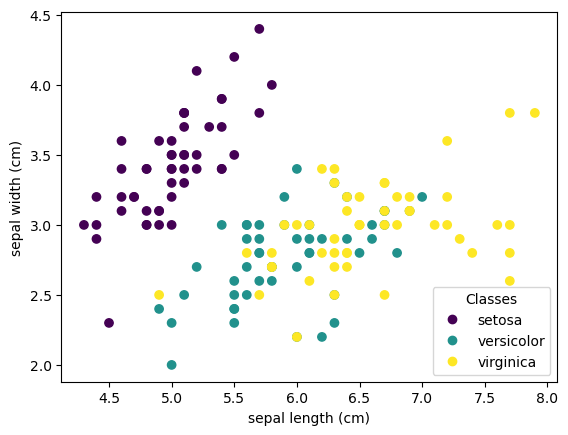

In [34]:
iris = datasets.load_iris()

_, ax = plt.subplots()
scatter = ax.scatter(iris.data[:, 0], iris.data[:, 1], c=iris.target)
ax.set(xlabel=iris.feature_names[0], ylabel=iris.feature_names[1])
_ = ax.legend(
    scatter.legend_elements()[0], iris.target_names, loc="lower right", title="Classes"
)

In [35]:
inputs = iris.data

# Since each prediction is a vector with a score for each of the three species,
# we make each target a vector with a 1 for the correct species and a 0 for the others (one-hot).
targets = np.zeros((len(iris.data), 3))
for i, t in enumerate(iris.target):
    targets[i, t] = 1


def accuracy(predictions, targets):
    one_hot_predictions = np.zeros(predictions.shape)

    for i, prediction in enumerate(predictions):
        one_hot_predictions[i, np.argmax(prediction)] = 1
    return accuracy_score(one_hot_predictions, targets)

**a) Sizes.** The input size is the number of features, 4
(`inputs.shape == (150, 4)`); the output size is the number of classes, 3,
one score per species, matching the one-hot targets of shape (150, 3).

**b) The network.** Two layers, 4 → 8 → 3, with `[sigmoid, softmax]`, in the
batched convention.


In [36]:
network_input_size = inputs.shape[1]      # 4 features
layer_output_sizes = [100, 100, targets.shape[1]]  # 8 hidden nodes, 3 classes
activation_funcs = [ReLU, softmax]
layers = create_layers_batch(network_input_size, layer_output_sizes)
print(inputs.shape, [W.shape for W, b in layers])

(150, 4) [(4, 100), (100, 100), (100, 3)]


**c)** The whole data set goes through the network in one call.

In [39]:
predictions = feed_forward_batch(inputs, layers, activation_funcs)
print(predictions.shape)
print(predictions[:5])

(150, 100)
[[7.85311329e-063 1.47024767e-025 2.82036657e-075 1.72973169e-057
  3.24496659e-032 1.44396395e-035 7.92298063e-035 3.37772253e-033
  5.41582591e-047 1.05656389e-055 8.58007374e-056 3.98951881e-064
  2.60684722e-046 4.40114345e-067 5.98056004e-060 2.08463272e-069
  1.70215178e-037 6.05267456e-042 4.39422988e-086 2.22261898e-070
  3.10084414e-051 8.16096576e-094 6.41426313e-074 6.84991608e-070
  4.02985438e-019 1.19632877e-023 3.61101105e-038 8.41250899e-065
  4.11998777e-043 1.35494990e-068 1.05425994e-038 1.84980246e-056
  3.40249076e-041 1.32617474e-037 1.38376417e-048 1.67638780e-053
  3.86349499e-044 1.18053754e-060 5.78071150e-062 5.30136420e-033
  2.69976311e-046 2.97625029e-034 1.02654255e-055 6.92272458e-014
  5.00003418e-079 3.02908296e-062 1.00114221e-022 2.21691044e-042
  6.99787148e-064 4.00839033e-030 2.72802831e-075 2.90468326e-053
  1.77124437e-044 2.11121335e-028 6.77864980e-080 1.55753894e-060
  1.24412555e-039 8.11503954e-072 3.71622747e-027 1.11034166e-003

**d) Accuracy of an untrained network.** We recreate the network six
times (with a fixed seed, so that the numbers below are reproducible).
Guessing one of three classes at random gives $1/3 \approx 33\%$ on
average, and since the classes are balanced (50 flowers each) *any* rule that
ignores the input gives exactly 1/3. That is what an untrained network
typically does: with random weights the winning class is the same for
(almost) every flower, so the accuracy is exactly that of guessing. Once in
a while the random boundaries happen to separate one species (usually the
well-separated setosa) and the accuracy jumps to 2/3; it could equally well
drop below 1/3. Note also the last column: the largest softmax probability
is often 0.9 or more. The untrained network is *confident*, it is just
confidently wrong — the confidence of a network's output carries no
information before training (and, as Section 5.12 discusses, must be
calibrated even after).


In [38]:
print("untrained accuracy:", accuracy(predictions, targets))
np.random.seed(2026)
print("recreated networks:  accuracy   predicted classes (counts)   mean largest probability")
for trial in range(6):
    layers_trial = create_layers_batch(network_input_size, layer_output_sizes)
    pred_trial = feed_forward_batch(inputs, layers_trial, activation_funcs)
    print("           trial %d:    %.3f      %s                  %.2f"
          % (trial, accuracy(pred_trial, targets),
             np.bincount(np.argmax(pred_trial, axis=1), minlength=3),
             float(np.mean(np.max(pred_trial, axis=1)))))

ValueError: inconsistent shapes

           trial 4:    0.667      [ 50   0 100]                  0.56
           trial 5:    0.333      [  0   0 150]                  0.75


*Remark on the initialisation.* The hidden layer receives the raw iris
features (values between 0.1 and 7.9) with weights of size one, so its
sigmoids are often saturated. Standardising the inputs and drawing the
weights with standard deviation $1/\sqrt{\text{inputs}}$ (Section 8.10)
are the first two things to do before training; we use both in exercise 7.


# Exercise 7 — training (optional)

The cost function is the multiclass cross entropy
$C = -\sum_{i}\sum_k y_{ik}\ln a_{ik}$ (Eq. (5.28) of the lecture notes),
summed over the samples and the classes; with one-hot targets only the
term of the correct class survives, so $C$ is minus the sum of the
log-probabilities the network assigns to the correct classes.


In [25]:
def cross_entropy(predict, target):
    return jnp.sum(-target * jnp.log(predict))


def cost(input, layers, activation_funcs, target):
    predict = feed_forward_batch(input, layers, activation_funcs)
    return cross_entropy(predict, target)


gradient_func = jax.grad(
    cost, argnums=1
)  # Taking the gradient wrt. the second input to the cost function, i.e. the layers

**a) Shapes of the gradients.** The gradient of a scalar with respect to
an array has the shape of that array: $\partial C/\partial W$ has the shape
of $W$ and $\partial C/\partial b$ the shape of $b$, for every layer. Here:
(4, 8) and (8,) for the first layer, (8, 3) and (3,) for the second.

**b) What `jax.grad` returns and does.** `jax.grad(cost, argnums=1)` is a
new function with the same arguments as `cost` that returns, instead of the
cost, its gradient with respect to the second argument. Because that
argument is a list of tuples of arrays, the result has exactly the same
structure (a "pytree" in JAX language): a list of `(dW, db)` tuples. To
compute it, JAX records the operations of the forward pass and applies the
chain rule backwards through them — *reverse-mode automatic
differentiation* (Section 4.14). For a layered network this is the
backpropagation algorithm of Section [8.8](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#backpropagation),
which you will write by hand next week; the numbers are the same.


In [26]:
layers_grad = gradient_func(
    inputs, layers, activation_funcs, targets
)  # Don't change this

for (W, b), (W_g, b_g) in zip(layers, layers_grad):
    print("W", W.shape, "-> dW", W_g.shape, "   b", b.shape, "-> db", b_g.shape)
print(type(layers_grad), type(layers_grad[0][0]))

W (4, 8) -> dW (4, 8)    b (8,) -> db (8,)
W (8, 3) -> dW (8, 3)    b (3,) -> db (3,)
<class 'list'> <class 'jaxlib.xla_extension.ArrayImpl'>


**c) `train_network`.** One step of plain gradient descent per epoch,
$W \leftarrow W - \gamma\,\partial C/\partial W$ and the same for $b$,
building a new list of layers each time.


In [27]:
def train_network(
    inputs, layers, activation_funcs, targets, gamma=0.001, epochs=100
):
    for i in range(epochs):
        layers_grad = gradient_func(inputs, layers, activation_funcs, targets)
        layers = [(W - gamma * W_g, b - gamma * b_g) for (W, b), (W_g, b_g) in zip(layers, layers_grad)]
    return layers

**d) Which gradient method?** The whole data set enters every update, so
this is plain (full-batch) **gradient descent** with a fixed learning rate
$\gamma$ (Section 4.3) — not stochastic gradient descent, which would use
minibatches, and without momentum or adaptive learning rates.

**e) Training.** We standardise the inputs (mean 0, standard deviation 1
per feature) and draw the initial weights with standard deviation
$1/\sqrt{\text{inputs}}$, both for the reason given after exercise 6.
With the cost summed over the 150 samples the gradient is 150 times larger
than for a mean, so a small learning rate such as $\gamma = 0.001$ is
appropriate. We record the cost and the accuracy every 25 epochs.


epoch    cost   accuracy
    0   167.15   0.333
  200    47.24   0.927
  400    31.24   0.960
  600    22.09   0.973
  800    17.07   0.973
 1000    14.20   0.973


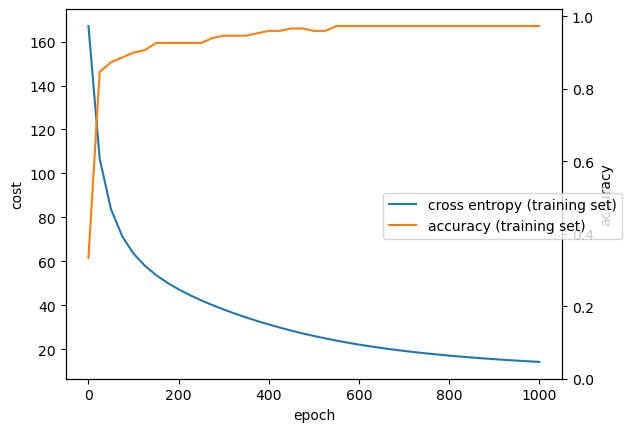

In [28]:
X_std = (inputs - inputs.mean(axis=0)) / inputs.std(axis=0)   # standardised features

np.random.seed(2026)
layers0 = [(np.random.randn(n_in, n_out) / np.sqrt(n_in), np.zeros(n_out))
           for n_in, n_out in [(4, 8), (8, 3)]]

gamma, epochs, every = 0.001, 1000, 25
history = []
layers_t = layers0
for epoch in range(0, epochs + 1, every):
    pred = feed_forward_batch(X_std, layers_t, activation_funcs)
    history.append((epoch, float(cost(X_std, layers_t, activation_funcs, targets)), accuracy(pred, targets)))
    if epoch < epochs:
        layers_t = train_network(X_std, layers_t, activation_funcs, targets, gamma=gamma, epochs=every)

history = np.array(history)
print("epoch    cost   accuracy")
for e, c, a in history[::8]:
    print("%5d  %7.2f   %.3f" % (e, c, a))

fig, ax1 = plt.subplots()
ax1.plot(history[:, 0], history[:, 1], label="cross entropy (training set)")
ax1.set_xlabel("epoch"); ax1.set_ylabel("cost")
ax2 = ax1.twinx()
ax2.plot(history[:, 0], history[:, 2], color="C1", label="accuracy (training set)")
ax2.set_ylabel("accuracy"); ax2.set_ylim(0, 1.02)
fig.legend(loc="center right"); plt.show()

**f) How high, and is it useful?** With enough epochs (or a larger
network) the training accuracy on the iris data goes to 98–100%: the three
species are almost linearly separable in the four features, and a network
with 59 parameters can draw the few boundaries needed to fit 150 points.
But this is a *training-set* accuracy: the same flowers were used to fit the
weights and to score them, so the number says nothing about how the network
would do on new flowers. Without a train/test split or cross-validation
(Section [3.14](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter3.html)) it is not a useful measure of the model.
In Project 2 the accuracy is always reported on test data.


In [29]:
layers_long = train_network(X_std, layers_t, activation_funcs, targets, gamma=gamma, epochs=4000)
pred_long = feed_forward_batch(X_std, layers_long, activation_funcs)
print("training accuracy after 5000 epochs:", accuracy(pred_long, targets))

# the honest number: fit on 80% of the flowers, score on the other 20%
from sklearn.model_selection import train_test_split
X_tr, X_te, y_tr, y_te = train_test_split(X_std, targets, test_size=0.2, random_state=2026, stratify=iris.target)
layers_split = train_network(X_tr, layers0, activation_funcs, y_tr, gamma=gamma, epochs=5000)
print("train accuracy %.3f   test accuracy %.3f"
      % (accuracy(feed_forward_batch(X_tr, layers_split, activation_funcs), y_tr),
         accuracy(feed_forward_batch(X_te, layers_split, activation_funcs), y_te)))

training accuracy after 5000 epochs: 0.98
train accuracy 0.992   test accuracy 0.967


train accuracy 0.992   test accuracy 0.967


## Summary

* A dense layer is $z = Wx + b$, $a = f(z)$; the shapes of $W$ and $b$ fix
  the architecture, and the output of one layer is the input of the next.
* Without activation functions the whole network is one affine map; the
  non-linearity between the layers is what makes it more than linear
  regression.
* Keeping the parameters in a list of `(W, b)` tuples and the activations
  in a list of functions gives code that works for any depth and width.
* Batched inputs: samples in rows, $Z = XW + b$ with $W$ of shape
  (inputs, outputs) — the convention of the lecture notes, of Monday's code
  and of next week's backpropagation exercises.
* The softmax turns scores into a distribution over classes; paired with the
  cross entropy it gives the simple output error $a - y$ that you will meet
  next week (Eq. (8.69)).
* `jax.grad` differentiates the whole forward pass by reverse-mode
  automatic differentiation; next week you reproduce its numbers by hand.
* An accuracy is only meaningful on data the network has not been trained
  on.
